In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import fbeta_score
from sklearn.preprocessing import LabelEncoder

In [20]:
# 1. โหลดข้อมูลและเตรียมการรวมร่าง
# =========================================
train_df = pd.read_csv('/kaggle/input/competitions/super-ai-engineer-ss-6-heart-disease-prediction/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/super-ai-engineer-ss-6-heart-disease-prediction/test.csv')

num_train = len(train_df)

# อุดรอยรั่ว Target ด้วย Mode
most_freq_y = train_df['History of HeartDisease or Attack'].mode()[0]
y = train_df['History of HeartDisease or Attack'].fillna(
    train_df['History of HeartDisease or Attack'].mode()[0]
).map({'Yes': 1, 'No': 0})

# นำ X มาต่อกันเพื่อเตรียมแปลงร่าง
X_train_raw = train_df.drop(columns=['History of HeartDisease or Attack', 'ID'])
X_test_raw = test_df.drop(columns=['ID'])
all_X = pd.concat([X_train_raw, X_test_raw], axis=0).reset_index(drop=True)

In [3]:
# 1. โหลดข้อมูล (สมมติว่าเป็นชุด Train)
train_df = pd.read_csv('/kaggle/input/competitions/super-ai-engineer-ss-6-heart-disease-prediction/train.csv')

# --- กระบวนการตรวจสอบก่อนลบ ---
print("จำนวนบรรทัดก่อนลบ:", len(train_df))
print("จำนวนค่าว่างในแต่ละคอลัมน์ก่อนลบ:\n", train_df.isnull().sum())
print("-" * 30)

# 2. ทำการลบบรรทัดที่มี NaN ออก
# คำสั่ง dropna() โดยปริยาย (axis=0) จะไล่เช็คทีละบรรทัด 
# ถ้าเจอบรรทัดไหนมี NaN แม้แต่ช่องเดียว มันจะเตะบรรทัดนั้นทิ้งทั้งบรรทัด
train_df_clean = train_df.dropna()

# --- กระบวนการตรวจสอบหลังลบ ---
print("จำนวนบรรทัดหลังลบ:", len(train_df_clean))
print("จำนวนค่าว่างในแต่ละคอลัมน์หลังลบ:\n", train_df_clean.isnull().sum())

# 3. เตรียมข้อมูลไปสอนโมเดลต่อไป (ตัด ID ทิ้งตามกระบวนการปกติ)
X_train_raw = train_df_clean.drop(columns=['History of HeartDisease or Attack', 'ID'])
y_train_raw = train_df_clean['History of HeartDisease or Attack']

จำนวนบรรทัดก่อนลบ: 223084
จำนวนค่าว่างในแต่ละคอลัมน์ก่อนลบ:
 ID                                            0
History of HeartDisease or Attack          1694
High Blood Pressure                           0
Told High Cholesterol                     32186
Cholesterol Checked                           0
Body Mass Index                           11782
Smoked 100+ Cigarettes                        1
Diagnosed Stroke                              0
Diagnosed Diabetes                            3
Leisure Physical Activity                     0
Heavy Alcohol Consumption                     0
Health Care Coverage                          0
Doctor Visit Cost Barrier                     1
General Health                                1
Difficulty Walking                            3
Sex                                           0
Education Level                               0
Income Level                                  0
Age                                           0
Vegetable or Fruit Intake (

In [8]:
health_map  = {'Very Poor':1,'Poor':2,'Fair':3,'Good':4,'Very good':5,'Excellent':6}
edu_map     = {
    'Never attended school or only kindergarten':1,
    'Grades 1 through 8 (Elementary)':2,
    'Some high school':3,
    'High school graduate':4,
    'Some college or technical school':5,
    'College graduate':6
}
income_map  = {
    'Less than $10,000':1,
    '($10,000 to less than $15,000':2,
    '$15,000 to less than $20,000':3,
    '$20,000 to less than $25,000':4,
    '$25,000 to less than $35,000':5,
    '$35,000 to less than $50,000':6,
    '$50,000 to less than $75,000':7,
    '$75,000 or more':8
}

all_X['General Health']  = all_X['General Health'].map(health_map)
all_X['Education Level'] = all_X['Education Level'].map(edu_map)
all_X['Income Level']    = all_X['Income Level'].map(income_map)

# 5. Binary columns: Yes/No → 1/0
binary_cols = [
    'High Blood Pressure','Told High Cholesterol','Cholesterol Checked',
    'Smoked 100+ Cigarettes','Diagnosed Stroke','Diagnosed Diabetes',
    'Leisure Physical Activity','Heavy Alcohol Consumption',
    'Health Care Coverage','Doctor Visit Cost Barrier',
    'Difficulty Walking','Vegetable or Fruit Intake (1+ per Day)'
]
yes_no_map = {'Yes':1, 'No':0}
for col in binary_cols:
    if col in all_X.columns:
        all_X[col] = all_X[col].map(yes_no_map)

# Sex
all_X['Sex'] = all_X['Sex'].map({'Male':1, 'Female':0})

In [12]:
# 6. Fill NaN ที่เหลือด้วย mode (ไม่ทิ้งข้อมูล!)
for col in all_X.columns:
    mode_vals = all_X[col].mode()
    if len(mode_vals) > 0:  # เช็คก่อนว่า mode มีค่า
        all_X[col] = all_X[col].fillna(mode_vals[0])

In [13]:
encoder = LabelEncoder()
for col in all_X.columns:
    if all_X[col].dtype == 'object' or all_X[col].dtype == 'bool':
        all_X[col] = encoder.fit_transform(all_X[col].astype(str))

In [14]:
all_X['Is_Senior'] = (all_X['Age'] >= 60).astype(int)
all_X['Risk_Combo'] = all_X['High Blood Pressure'] + all_X['Told High Cholesterol']

# แยกร่าง Train / Test
X_train = all_X.iloc[:num_train]
X_test = all_X.iloc[num_train:]

# เตรียมตัวเฉลย
y_encoder = LabelEncoder()
y_train = y_encoder.fit_transform(y_raw.astype(str))

In [21]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
model.fit(X_tr, y_tr)

y_pred = model.predict(X_val)
score  = fbeta_score(y_val, y_pred, beta=2)  # ปรับ beta ตาม metric ของ competition
print(f"F-beta Score: {score:.4f}")

# 9. Predict และ submit
test_pred = model.predict(X_test)
submission = pd.DataFrame({'ID': test_df['ID'], 'History of HeartDisease or Attack': test_pred})
submission.to_csv('submissionheart.csv', index=False)

F-beta Score: 0.1044


ดู imbalance

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import fbeta_score

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y, test_size=0.2, random_state=42, stratify=y  # เพิ่ม stratify
)

# เช็คก่อนว่า imbalance แค่ไหน
print(y_tr.value_counts(normalize=True))

model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',   # ให้น้ำหนัก class ที่น้อยกว่ามากขึ้น
    random_state=42,
    n_jobs=-1
)
model.fit(X_tr, y_tr)

# ปรับ threshold แทนที่จะใช้ 0.5 default
y_prob = model.predict_proba(X_val)[:, 1]

# หา threshold ที่ดีที่สุด
best_score, best_thresh = 0, 0.5
for thresh in [i/100 for i in range(10, 60, 2)]:
    y_pred = (y_prob >= thresh).astype(int)
    score = fbeta_score(y_val, y_pred, beta=2)
    if score > best_score:
        best_score, best_thresh = score, thresh

print(f"Best Threshold: {best_thresh:.2f}")
print(f"Best F-beta Score: {best_score:.4f}")

History of HeartDisease or Attack
0    0.91901
1    0.08099
Name: proportion, dtype: float64
Best Threshold: 0.10
Best F-beta Score: 0.2729


In [25]:
from xgboost import XGBClassifier
from sklearn.metrics import fbeta_score

neg = (y_tr == 0).sum()
pos = (y_tr == 1).sum()
print(f"scale_pos_weight = {neg/pos:.2f}")  # ควรได้ประมาณ 11

model = XGBClassifier(
    n_estimators=500,
    scale_pos_weight=neg/pos,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric='aucpr'  # metric ที่เหมาะกับ imbalanced data
)
model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    verbose=100
)

# หา threshold ที่ดีที่สุด
y_prob = model.predict_proba(X_val)[:, 1]

best_score, best_thresh = 0, 0.5
for thresh in [i/100 for i in range(5, 60, 1)]:
    y_pred = (y_prob >= thresh).astype(int)
    score = fbeta_score(y_val, y_pred, beta=2)
    if score > best_score:
        best_score, best_thresh = score, thresh

print(f"Best Threshold: {best_thresh:.2f}")
print(f"Best F-beta Score: {best_score:.4f}")

scale_pos_weight = 11.35
[0]	validation_0-aucpr:0.18593
[100]	validation_0-aucpr:0.18921
[200]	validation_0-aucpr:0.18671
[300]	validation_0-aucpr:0.18572
[400]	validation_0-aucpr:0.18526
[499]	validation_0-aucpr:0.18432
Best Threshold: 0.52
Best F-beta Score: 0.4262


lightgbm

In [26]:
from lightgbm import LGBMClassifier
from sklearn.metrics import fbeta_score

neg = (y_tr == 0).sum()
pos = (y_tr == 1).sum()

model = LGBMClassifier(
    n_estimators=1000,
    scale_pos_weight=neg/pos,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=20,
    random_state=42,
    n_jobs=-1,
)
model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    callbacks=[
        __import__('lightgbm').early_stopping(50),   # หยุดถ้าไม่ดีขึ้นใน 50 rounds
        __import__('lightgbm').log_evaluation(100)
    ]
)

# หา threshold
y_prob = model.predict_proba(X_val)[:, 1]

best_score, best_thresh = 0, 0.5
for thresh in [i/100 for i in range(5, 60, 1)]:
    y_pred = (y_prob >= thresh).astype(int)
    score = fbeta_score(y_val, y_pred, beta=2)
    if score > best_score:
        best_score, best_thresh = score, thresh

print(f"Best Threshold: {best_thresh:.2f}")
print(f"Best F-beta Score: {best_score:.4f}")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 14454, number of negative: 164013
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004684 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 341
[LightGBM] [Info] Number of data points in the train set: 178467, number of used features: 3
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080990 -> initscore=-2.428975
[LightGBM] [Info] Start training from score -2.428975
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

essemble

In [28]:
# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=500,
    scale_pos_weight=neg/pos,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

# Train LightGBM
lgb_model = LGBMClassifier(
    n_estimators=1000,
    scale_pos_weight=neg/pos,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)
lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    callbacks=[
        __import__('lightgbm').early_stopping(50),
        __import__('lightgbm').log_evaluation(100)
    ]
)

# Ensemble
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]
y_prob_lgb = lgb_model.predict_proba(X_val)[:, 1]
y_prob_ensemble = (y_prob_xgb + y_prob_lgb) / 2

best_score, best_thresh = 0, 0.5
for thresh in [i/100 for i in range(5, 60, 1)]:
    y_pred = (y_prob_ensemble >= thresh).astype(int)
    score = fbeta_score(y_val, y_pred, beta=2)
    if score > best_score:
        best_score, best_thresh = score, thresh

print(f"Ensemble Best Threshold: {best_thresh:.2f}")
print(f"Ensemble Best F-beta Score: {best_score:.4f}")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 14454, number of negative: 164013
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003214 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 341
[LightGBM] [Info] Number of data points in the train set: 178467, number of used features: 3
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080990 -> initscore=-2.428975
[LightGBM] [Info] Start training from score -2.428975
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

In [29]:
# แก้ชื่อคอลัมน์ก่อน train ทุกอย่าง
X_tr.columns     = X_tr.columns.str.replace(' ', '_')
X_val.columns    = X_val.columns.str.replace(' ', '_')
X_train.columns  = X_train.columns.str.replace(' ', '_')
X_test.columns   = X_test.columns.str.replace(' ', '_')

print(f"Features: {X_tr.shape[1]}")  # ควรได้ 18
print(X_tr.columns.tolist())

Features: 20
['High_Blood_Pressure', 'Told_High_Cholesterol', 'Cholesterol_Checked', 'Body_Mass_Index', 'Smoked_100+_Cigarettes', 'Diagnosed_Stroke', 'Diagnosed_Diabetes', 'Leisure_Physical_Activity', 'Heavy_Alcohol_Consumption', 'Health_Care_Coverage', 'Doctor_Visit_Cost_Barrier', 'General_Health', 'Difficulty_Walking', 'Sex', 'Education_Level', 'Income_Level', 'Age', 'Vegetable_or_Fruit_Intake_(1+_per_Day)', 'Is_Senior', 'Risk_Combo']


In [32]:
print(X_tr.dtypes)
print(X_tr.isnull().sum())

High_Blood_Pressure                       float64
Told_High_Cholesterol                     float64
Cholesterol_Checked                       float64
Body_Mass_Index                           float64
Smoked_100+_Cigarettes                    float64
Diagnosed_Stroke                          float64
Diagnosed_Diabetes                        float64
Leisure_Physical_Activity                 float64
Heavy_Alcohol_Consumption                 float64
Health_Care_Coverage                      float64
Doctor_Visit_Cost_Barrier                 float64
General_Health                            float64
Difficulty_Walking                        float64
Sex                                       float64
Education_Level                           float64
Income_Level                              float64
Age                                         int64
Vegetable_or_Fruit_Intake_(1+_per_Day)    float64
Is_Senior                                   int64
Risk_Combo                                float64


In [33]:
# ดูค่าจริงๆ ในข้อมูลดิบก่อน map
train_df = pd.read_csv('/kaggle/input/competitions/super-ai-engineer-ss-6-heart-disease-prediction/train.csv')
test_df  = pd.read_csv('/kaggle/input/competitions/super-ai-engineer-ss-6-heart-disease-prediction/test.csv')

X_train_raw = train_df.drop(columns=['History of HeartDisease or Attack', 'ID'])
X_test_raw  = test_df.drop(columns=['ID'])
all_X = pd.concat([X_train_raw, X_test_raw], axis=0).reset_index(drop=True)

# เช็คค่าจริงในแต่ละคอลัมน์
for col in all_X.columns:
    print(f"\n{col}:")
    print(all_X[col].value_counts().head(5))


High Blood Pressure:
High Blood Pressure
No     178703
Yes    118742
Name: count, dtype: int64

Told High Cholesterol:
Told High Cholesterol
No     153153
Yes    112106
Name: count, dtype: int64

Cholesterol Checked:
Cholesterol Checked
Yes    255389
No      42056
Name: count, dtype: int64

Body Mass Index:
Body Mass Index
24.92    284
26.63    283
26.48    280
25.76    270
24.93    267
Name: count, dtype: int64

Smoked 100+ Cigarettes:
Smoked 100+ Cigarettes
No     167341
Yes    130103
Name: count, dtype: int64

Diagnosed Stroke:
Diagnosed Stroke
No     286276
Yes     11169
Name: count, dtype: int64

Diagnosed Diabetes:
Diagnosed Diabetes
No     256980
Yes     40462
Name: count, dtype: int64

Leisure Physical Activity:
Leisure Physical Activity
Yes    223168
No      74277
Name: count, dtype: int64

Heavy Alcohol Consumption:
Heavy Alcohol Consumption
No     280325
Yes     17120
Name: count, dtype: int64

Health Care Coverage:
Health Care Coverage
Yes    277499
No      19946
Name: cou

mapไม่ตรง

In [34]:
# Ordinal mapping (แก้ให้ตรงกับค่าจริง)
health_map = {'Very Poor':1, 'Poor':2, 'Fair':3, 'Good':4, 'Excellent':5}

edu_map = {
    'Elementary': 1,
    'Some high school': 2,
    'High school graduate': 3,
    'Some college or technical school': 4,
    'College graduate': 5
}

income_map = {
    'Less than $10,000': 1,
    '$10,000 to less than $15,000': 2,
    '$15,000 to less than $20,000': 3,
    '$20,000 to less than $25,000': 4,
    '$25,000 to less than $35,000': 5,
    '$35,000 to less than $50,000': 6,
    '$50,000 to less than $75,000': 7,
    '$75,000 or more': 8
}

all_X['General Health']  = all_X['General Health'].map(health_map)
all_X['Education Level'] = all_X['Education Level'].map(edu_map)
all_X['Income Level']    = all_X['Income Level'].map(income_map)

# Binary Yes/No → 1/0
binary_cols = [
    'High Blood Pressure', 'Told High Cholesterol', 'Cholesterol Checked',
    'Smoked 100+ Cigarettes', 'Diagnosed Stroke', 'Diagnosed Diabetes',
    'Leisure Physical Activity', 'Heavy Alcohol Consumption',
    'Health Care Coverage', 'Doctor Visit Cost Barrier',
    'Difficulty Walking', 'Vegetable or Fruit Intake (1+ per Day)'
]
yes_no_map = {'Yes': 1, 'No': 0}
for col in binary_cols:
    all_X[col] = all_X[col].map(yes_no_map)

all_X['Sex'] = all_X['Sex'].map({'Male': 1, 'Female': 0})

# Fill NaN ที่เหลือ
for col in all_X.columns:
    mode_vals = all_X[col].mode()
    if len(mode_vals) > 0:
        all_X[col] = all_X[col].fillna(mode_vals[0])

# เช็คว่าไม่มี NaN เหลือ
print("NaN ที่เหลือ:", all_X.isnull().sum().sum())
print("ตัวอย่างข้อมูล:")
print(all_X.head(3))

NaN ที่เหลือ: 0
ตัวอย่างข้อมูล:
   High Blood Pressure  Told High Cholesterol  Cholesterol Checked  \
0                    1                    1.0                    1   
1                    0                    0.0                    0   
2                    1                    1.0                    1   

   Body Mass Index  Smoked 100+ Cigarettes  Diagnosed Stroke  \
0            40.68                     1.0                 0   
1            24.36                     1.0                 0   
2            27.33                     0.0                 0   

   Diagnosed Diabetes  Leisure Physical Activity  Heavy Alcohol Consumption  \
0                 0.0                          0                          0   
1                 0.0                          1                          0   
2                 0.0                          0                          0   

   Health Care Coverage  Doctor Visit Cost Barrier  General Health  \
0                     1                    

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import fbeta_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# แยก train/test กลับ
num_train = len(train_df)
X_train = all_X.iloc[:num_train].reset_index(drop=True)
X_test  = all_X.iloc[num_train:].reset_index(drop=True)

# Target
y = train_df['History of HeartDisease or Attack'].fillna(
    train_df['History of HeartDisease or Attack'].mode()[0]
).map({'Yes': 1, 'No': 0})

# Split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y, test_size=0.2, random_state=42, stratify=y
)

neg = (y_tr == 0).sum()
pos = (y_tr == 1).sum()
print(f"Train size: {len(X_tr)}, Pos: {pos}, Neg: {neg}, Ratio: {neg/pos:.1f}x")

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=500, scale_pos_weight=neg/pos,
    learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1,
)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

# LightGBM
lgb_model = LGBMClassifier(
    n_estimators=1000, scale_pos_weight=neg/pos,
    learning_rate=0.05, max_depth=6, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8,
    min_child_samples=20, random_state=42, n_jobs=-1,
)
lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    callbacks=[
        __import__('lightgbm').early_stopping(50),
        __import__('lightgbm').log_evaluation(100)
    ]
)

# Ensemble + หา threshold
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]
y_prob_lgb = lgb_model.predict_proba(X_val)[:, 1]
y_prob_ensemble = (y_prob_xgb + y_prob_lgb) / 2

best_score, best_thresh = 0, 0.5
for thresh in [i/100 for i in range(5, 60, 1)]:
    y_pred = (y_prob_ensemble >= thresh).astype(int)
    score = fbeta_score(y_val, y_pred, beta=2)
    if score > best_score:
        best_score, best_thresh = score, thresh

print(f"\nXGB alone:      {fbeta_score(y_val, (y_prob_xgb >= best_thresh).astype(int), beta=2):.4f}")
print(f"LGB alone:      {fbeta_score(y_val, (y_prob_lgb >= best_thresh).astype(int), beta=2):.4f}")
print(f"Ensemble:       {best_score:.4f}  (threshold: {best_thresh:.2f})")

Train size: 178467, Pos: 14454, Neg: 164013, Ratio: 11.3x
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 14454, number of negative: 164013
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012750 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 385
[LightGBM] [Info] Number of data points in the train set: 178467, number of used features: 18
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080990 -> initscore=-2.428975
[LightGBM] [Info] Start training from score -2.428975
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [

In [36]:
lgb_model = LGBMClassifier(
    n_estimators=1000, scale_pos_weight=neg/pos,
    learning_rate=0.05, max_depth=6, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8,
    min_child_samples=20, random_state=42, n_jobs=-1,
)
lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    eval_metric='average_precision',  # เปลี่ยนตรงนี้
    callbacks=[
        __import__('lightgbm').early_stopping(50, first_metric_only=True),
        __import__('lightgbm').log_evaluation(100)
    ]
)

# เช็ค LGB อย่างเดียวก่อน
y_prob_lgb = lgb_model.predict_proba(X_val)[:, 1]

best_score, best_thresh = 0, 0.5
for thresh in [i/100 for i in range(5, 60, 1)]:
    y_pred = (y_prob_lgb >= thresh).astype(int)
    score = fbeta_score(y_val, y_pred, beta=2)
    if score > best_score:
        best_score, best_thresh = score, thresh

print(f"LGB alone: {best_score:.4f}  (threshold: {best_thresh:.2f})")

# Ensemble
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]
y_prob_ensemble = (y_prob_xgb + y_prob_lgb) / 2

best_score_e, best_thresh_e = 0, 0.5
for thresh in [i/100 for i in range(5, 60, 1)]:
    y_pred = (y_prob_ensemble >= thresh).astype(int)
    score = fbeta_score(y_val, y_pred, beta=2)
    if score > best_score_e:
        best_score_e, best_thresh_e = score, thresh

print(f"Ensemble:  {best_score_e:.4f}  (threshold: {best_thresh_e:.2f})")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 14454, number of negative: 164013
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013023 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 385
[LightGBM] [Info] Number of data points in the train set: 178467, number of used features: 18
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080990 -> initscore=-2.428975
[LightGBM] [Info] Start training from score -2.428975
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: 

****public score 0.55****

In [37]:
# Predict test set ด้วย LGB เดี่ยว
y_prob_test = lgb_model.predict_proba(X_test)[:, 1]
test_pred = (y_prob_test >= 0.56).astype(int)  # ใช้ threshold ที่ดีที่สุด

submission = pd.DataFrame({
    'ID': test_df['ID'],
    'History of HeartDisease or Attack': pd.Series(test_pred).map({1: 'Yes', 0: 'No'})
})

# เช็คก่อน submit
print(submission['History of HeartDisease or Attack'].value_counts())
print(submission.head())

submission.to_csv('submissionlgb.csv', index=False)

History of HeartDisease or Attack
No     52260
Yes    22101
Name: count, dtype: int64
            ID History of HeartDisease or Attack
0  test_000001                                No
1  test_000002                                No
2  test_000003                               Yes
3  test_000004                                No
4  test_000005                                No


eda

/tmp/ipykernel_55/1456873292.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df_clean, x='History of HeartDisease or Attack', palette='Set2')


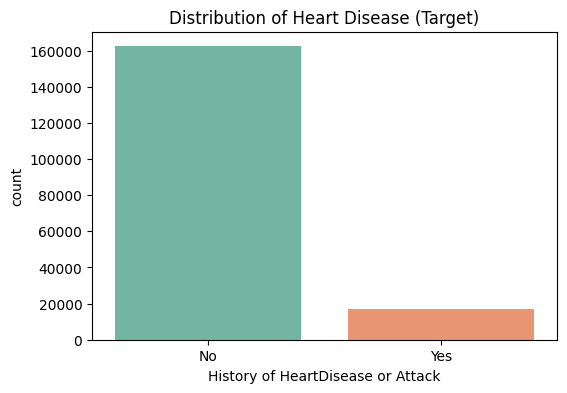

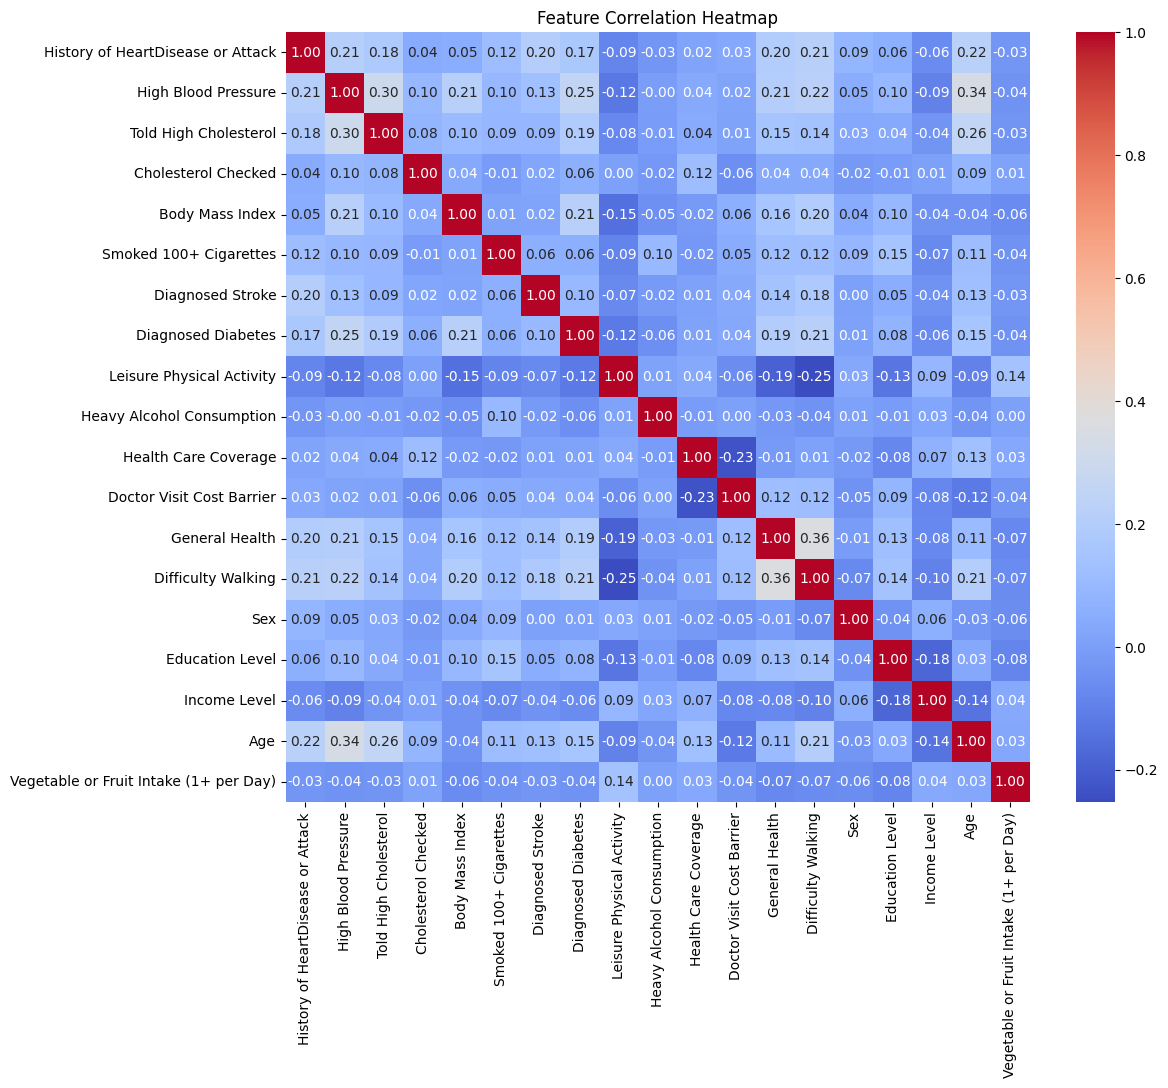

/tmp/ipykernel_55/1456873292.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df_clean, x='History of HeartDisease or Attack', y='Body Mass Index', palette='pastel')


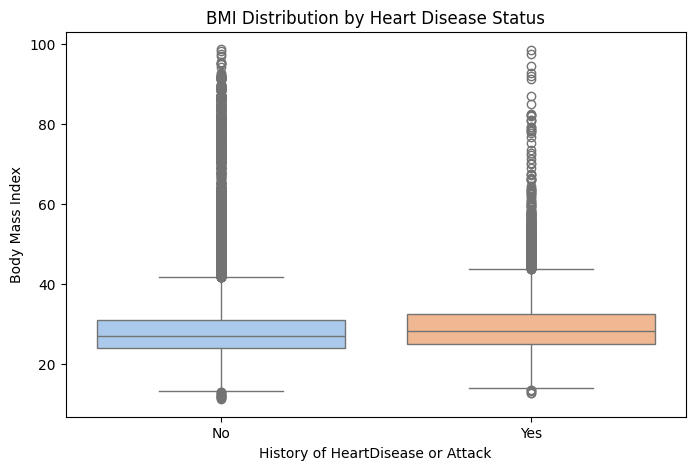

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# สมมติว่าใช้ train_df_clean ที่ลบค่าว่างออกแล้ว
# เพื่อให้สร้างกราฟความสัมพันธ์ได้ เราต้องแปลงข้อความชั่วคราวให้เป็นตัวเลขก่อน
eda_df = train_df_clean.copy()
encoder = LabelEncoder()
for col in eda_df.columns:
    if eda_df[col].dtype == 'object' or eda_df[col].dtype == 'bool':
        eda_df[col] = encoder.fit_transform(eda_df[col].astype(str))

# =======================================================
# Step 1: ดูสัดส่วนของเฉลย (Target Distribution)
# =======================================================
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df_clean, x='History of HeartDisease or Attack', palette='Set2')
plt.title('Distribution of Heart Disease (Target)')
plt.show()

# =======================================================
# Step 2: ดูความสัมพันธ์ของทุกปัจจัย (Correlation Heatmap)
# =======================================================
plt.figure(figsize=(12, 10))
# คำนวณค่าความสัมพันธ์และสร้างแผนภาพความร้อน
correlation_matrix = eda_df.drop(columns=['ID']).corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Feature Correlation Heatmap')
plt.show()

# =======================================================
# Step 3: เจาะลึกดูค่า BMI เทียบกับโรคหัวใจ (Feature vs Target)
# =======================================================
plt.figure(figsize=(8, 5))
# ใช้ Boxplot เพื่อดูว่าคนเป็นโรคกับไม่เป็นโรค มีค่า BMI ต่างกันไหม
sns.boxplot(data=train_df_clean, x='History of HeartDisease or Attack', y='Body Mass Index', palette='pastel')
plt.title('BMI Distribution by Heart Disease Status')
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3627 (\N{THAI CHARACTER HO HIP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **

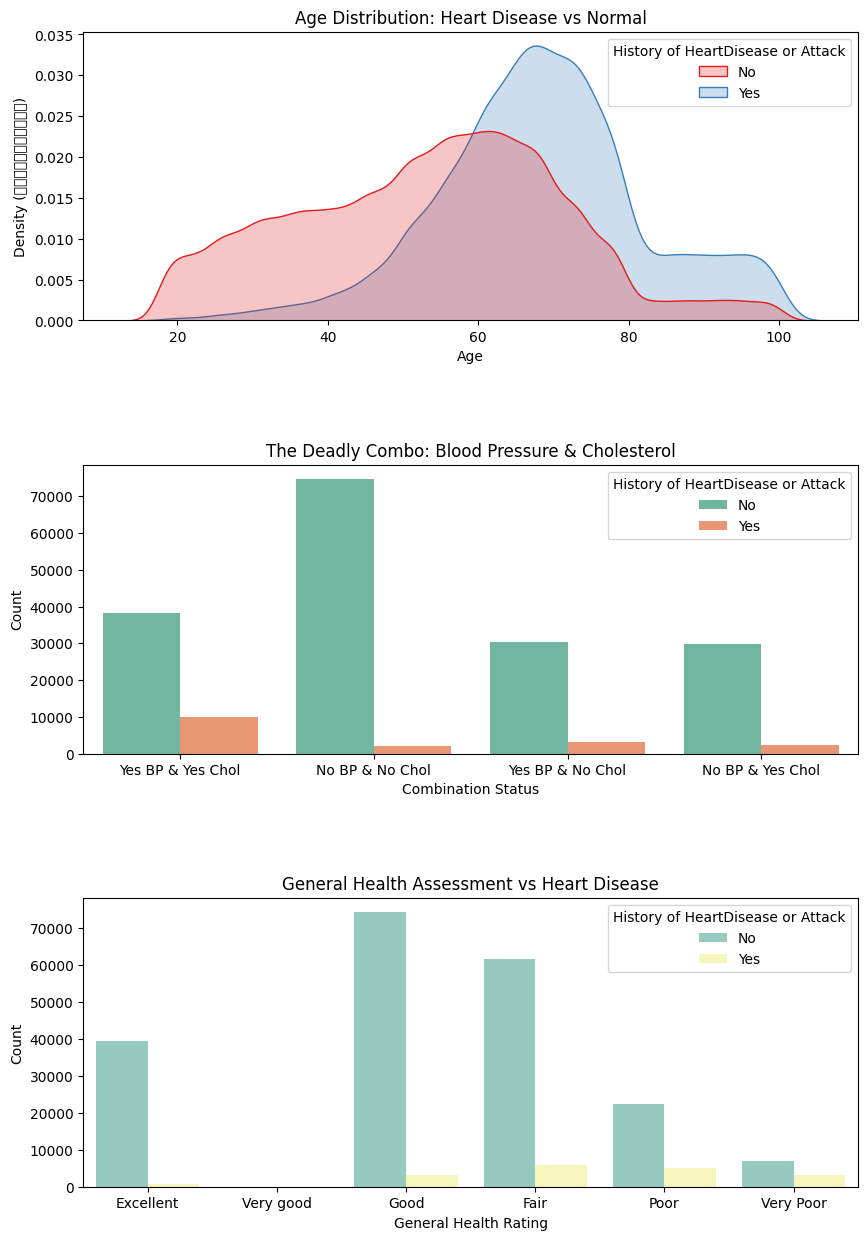

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# โหลดข้อมูล Train ต้นฉบับมาใช้ทำ EDA โดยเฉพาะ
eda_df = pd.read_csv('/kaggle/input/competitions/super-ai-engineer-ss-6-heart-disease-prediction/train.csv')

# เติมค่าว่างใน Target ด้วย Mode ก่อน เพื่อให้พล็อตกราฟได้ไม่ Error
most_freq_y = eda_df['History of HeartDisease or Attack'].mode()[0]
eda_df['History of HeartDisease or Attack'] = eda_df['History of HeartDisease or Attack'].fillna(most_freq_y)

# สร้าง Layout สำหรับแสดงกราฟ 3 ตัวติดกัน
fig, axes = plt.subplots(3, 1, figsize=(10, 15))
plt.subplots_adjust(hspace=0.5)

# =======================================================
# กราฟที่ 1: เจาะลึกช่วงอายุ (Age Distribution)
# =======================================================
# ใช้ KDE Plot ดูเป็นภูเขาว่าช่วงอายุไหนคนเป็นโรคเยอะสุด
sns.kdeplot(data=eda_df, x='Age', hue='History of HeartDisease or Attack', 
            fill=True, common_norm=False, palette='Set1', ax=axes[0])
axes[0].set_title('Age Distribution: Heart Disease vs Normal')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Density (ความหนาแน่น)')

# =======================================================
# กราฟที่ 2: The Deadly Combo (ความดันไขว้กับคอเลสเตอรอล)
# =======================================================
# สร้างคอลัมน์จำลองชั่วคราว เอามารวมกันให้เห็นภาพ
eda_df['Combo'] = eda_df['High Blood Pressure'] + " BP & " + eda_df['Told High Cholesterol'] + " Chol"
sns.countplot(data=eda_df, x='Combo', hue='History of HeartDisease or Attack', palette='Set2', ax=axes[1])
axes[1].set_title('The Deadly Combo: Blood Pressure & Cholesterol')
axes[1].set_xlabel('Combination Status')
axes[1].set_ylabel('Count')

# =======================================================
# กราฟที่ 3: สุขภาพโดยรวม (General Health)
# =======================================================
# จัดเรียงลำดับให้ดูง่าย (ถ้าข้อมูลมีค่าตามนี้)
health_order = ['Excellent', 'Very good', 'Good', 'Fair', 'Poor', 'Very Poor']
# เช็คก่อนว่ามีคำพวกนี้ไหม ถ้าไม่มีก็ให้กราฟจัดเรียงเอง
if eda_df['General Health'].isin(health_order).any():
    sns.countplot(data=eda_df, x='General Health', hue='History of HeartDisease or Attack', 
                  order=health_order, palette='Set3', ax=axes[2])
else:
    sns.countplot(data=eda_df, x='General Health', hue='History of HeartDisease or Attack', palette='Set3', ax=axes[2])
    
axes[2].set_title('General Health Assessment vs Heart Disease')
axes[2].set_xlabel('General Health Rating')
axes[2].set_ylabel('Count')

plt.show()